<hr>

<div align="center">

<h1>
Housing Affordability Dynamics:<br>
Price-to-Rent Ratios Across U.S. Metro Areas, 2020-August 2026
</h1>

<h3>
DATA 400 Individual Mini-Project · Fall 2026 · Thao Nguyen
</h3>

</div>

<hr>

## 1. Introduction

This project examines how the relationship between home values and rents changed across the 100 largest U.S. metropolitan areas from January 2020 through August 2026.

The main research question is:

> **How did the relationship between home values and rents change across the 100 largest U.S. metropolitan areas from January 2020 through August 2026, and which metros experienced the largest differences between home-price growth and rent growth?**

To study this relationship, I use Zillow's **Home Value Index (ZHVI)** and **Observed Rent Index (ZORI)**. I calculate the price-to-rent ratio (PTR), compare home-price growth with rent growth, and examine differences across metropolitan areas.

---

## 2. Data Sources

The analysis uses two Zillow Research datasets:

- **Zillow Home Value Index (ZHVI)** – measures typical home values.
- **Zillow Observed Rent Index (ZORI)** – measures typical observed rents.

The datasets contain monthly observations for U.S. metropolitan areas.

For this project, I focus on:

- The **100 largest metropolitan areas** based on Zillow's `SizeRank`
- January 2020 through August 2026
- Metropolitan areas that have sufficient coverage in both datasets

---


## 3. Data Preparation
---

In [3]:
# Import libraries for data analysis, visualization, and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import tools for standardizing data and performing K-means clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
# Load the Zillow Home Value Index (ZHVI) dataset
zhvi_raw = pd.read_csv(r"C:\Users\nguyenth\Downloads\Metro_zhvi.csv")
# Load the Zillow Observed Rent Index (ZORI) dataset
zori_raw = pd.read_csv(r"C:\Users\nguyenth\Downloads\Metro_zori.csv")
# Check the number of rows and columns in each dataset
print("ZHVI shape:", zhvi_raw.shape)
print("ZORI shape:", zori_raw.shape)

ZHVI shape: (895, 325)
ZORI shape: (750, 145)


In [3]:
# Display the first five rows of the ZHVI dataset
zhvi_raw.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,1/31/2000,2/29/2000,3/31/2000,4/30/2000,5/31/2000,...,11/30/2025,12/31/2025,1/31/2026,2/28/2026,3/31/2026,4/30/2026,5/31/2026,6/30/2026,7/31/2026,8/31/2026
0,102001,0,United States,country,NaN,123577.7596,123795.1725,124064.7965,124643.0871,125308.6302,...,365789.6372,366588.3871,367350.4469,368071.7143,368567.1729,368647.3330,368385.2914,368141.6470,368249.9967,368696.6847
1,394913,1,"New York, NY",msa,NY,220013.1236,220948.0553,221891.6461,223803.7261,225783.7513,...,708946.1759,712394.8245,715484.0295,719086.8624,722906.4551,725334.9455,726872.5619,728366.5978,731367.8023,735075.4727
2,753899,2,"Los Angeles, CA",msa,CA,221912.2698,222738.0650,223838.0163,226026.5500,228420.1197,...,948164.0844,952130.0482,954663.8971,955897.6374,955563.2371,953938.7202,952480.4871,950999.8555,951215.3473,952601.2482
3,394463,3,"Chicago, IL",msa,IL,156387.2539,156532.0229,156807.7381,157493.6490,158318.7173,...,344798.3611,346563.9567,348215.0633,349995.1823,351427.8526,352446.0177,353069.5214,353938.4329,355375.9316,357264.9354
4,394514,4,"Dallas, TX",msa,TX,129720.8578,129778.6360,129845.0578,130017.5484,130244.9726,...,367550.9885,367329.7124,366889.0939,366304.4825,365232.4178,363899.1484,362320.8086,361073.9506,360453.4980,360436.8173


**Selecting the 100 Largest Metropolitan Areas**

To focus the analysis on the largest U.S. metropolitan areas, I select observations classified as metropolitan statistical areas (MSAs) and rank them using Zillow's `SizeRank`. I then keep the 100 largest metropolitan areas for the analysis.

In [4]:
# Keep only metropolitan areas (MSAs) from the ZHVI dataset
msa = zhvi_raw[zhvi_raw["RegionType"] == "msa"]
# Sort metropolitan areas by Zillow's SizeRank
msa = msa.sort_values("SizeRank")
# Select the 100 largest metropolitan areas
top100 = msa.head(100)
# Keep only the columns needed to identify the selected metros
top100 = top100[["RegionID", "RegionName", "SizeRank"]]
# Display the first five selected metropolitan areas
top100.head()
# Check the number of metropolitan areas selected
print("Number of metros:", len(top100))

Number of metros: 100


In [5]:
# Check which selected metros are also available in the ZORI dataset
top100["RegionID"].isin(zori_raw["RegionID"]).value_counts()
# Keep only metros that appear in both the ZHVI and ZORI datasets
top100 = top100[top100["RegionID"].isin(zori_raw["RegionID"])]
# Check how many metros are available in both datasets
print("Metros available in both datasets:", len(top100))

Metros available in both datasets: 100


**Reshaping the Data into Monthly Format**

The ZHVI and ZORI datasets are originally in wide format, with each month represented as a separate column. I reshape both datasets into long format so that each observation represents one metro-month combination.

The final panel dataset contains:

- `RegionID`
- `date`
- `zhvi`
- `zori`
- `RegionName`
- `SizeRank`

The datasets are then merged using `RegionID` and `date`.

In [6]:
# The raw files have one column per month. I want one row for each metro-month observation instead.
id_cols = ["RegionID", "SizeRank", "RegionName", "RegionType", "StateName"]
start_date = pd.to_datetime("2020-01-01")
# Keep only the monthly columns from January 2020 onward
zhvi_months = [c for c in zhvi_raw.columns if c not in id_cols and pd.to_datetime(c) >= start_date]
zori_months = [c for c in zori_raw.columns if c not in id_cols and pd.to_datetime(c) >= start_date]
# Keep only the selected 100 metropolitan areas
zhvi_small = zhvi_raw[zhvi_raw["RegionID"].isin(top100["RegionID"])]
zori_small = zori_raw[zori_raw["RegionID"].isin(top100["RegionID"])]
# Convert the ZHVI data from wide format to long format
zhvi_long = zhvi_small.melt(
    id_vars="RegionID",
    value_vars=zhvi_months,
    var_name="date",
    value_name="zhvi"
)
# Convert the ZORI data from wide format to long format
zori_long = zori_small.melt(
    id_vars="RegionID",
    value_vars=zori_months,
    var_name="date",
    value_name="zori"
)
# Convert the date column from text to a datetime format
zhvi_long["date"] = pd.to_datetime(zhvi_long["date"])
zori_long["date"] = pd.to_datetime(zori_long["date"])
# Display the first five rows of the reshaped ZHVI dataset
zhvi_long.head()

,RegionID,date,zhvi
0,394913,2020-01-31,509099.7808
1,753899,2020-01-31,669786.0585
2,394463,2020-01-31,243955.2853
3,394514,2020-01-31,263767.5968
4,394692,2020-01-31,230309.7261


In [7]:
# Merge the ZHVI and ZORI datasets using metro ID and date
panel = pd.merge(
    zhvi_long,
    zori_long,
    on=["RegionID", "date"]
)
# Display the first five rows of the merged dataset
panel.head()

,RegionID,date,zhvi,zori
0,394913,2020-01-31,509099.7808,2583.127446
1,753899,2020-01-31,669786.0585,2266.695281
2,394463,2020-01-31,243955.2853,1548.867426
3,394514,2020-01-31,263767.5968,1294.811095
4,394692,2020-01-31,230309.7261,1338.696973


In [8]:
panel = pd.merge(
    panel,
    top100,
    on="RegionID"
)
panel.head()

,RegionID,date,zhvi,zori,RegionName,SizeRank
0,394913,2020-01-31,509099.7808,2583.127446,"New York, NY",1
1,753899,2020-01-31,669786.0585,2266.695281,"Los Angeles, CA",2
2,394463,2020-01-31,243955.2853,1548.867426,"Chicago, IL",3
3,394514,2020-01-31,263767.5968,1294.811095,"Dallas, TX",4
4,394692,2020-01-31,230309.7261,1338.696973,"Houston, TX",5


In [9]:
panel = panel.sort_values(
    ["RegionID", "date"]
).reset_index(drop=True)

print(panel.shape)
panel.head()

(8000, 6)


,RegionID,date,zhvi,zori,RegionName,SizeRank
0,394304,2020-01-31,155030.0159,839.603399,"Akron, OH",83
1,394304,2020-02-29,155936.5827,840.365569,"Akron, OH",83
2,394304,2020-03-31,157046.2056,850.081798,"Akron, OH",83
3,394304,2020-04-30,158193.8254,858.997292,"Akron, OH",83
4,394304,2020-05-31,158833.7624,872.556193,"Akron, OH",83


In [10]:
print("Missing values:")
print(panel[["zhvi", "zori"]].isna().sum())

Missing values:
zhvi    2
zori    0
dtype: int64


In [11]:
months = panel.groupby("RegionName")["date"].count()
print(months.describe())

count    100.0
mean      80.0
std        0.0
min       80.0
25%       80.0
50%       80.0
75%       80.0
max       80.0
Name: date, dtype: float64


In [12]:
minimum_months = 80 * 0.95
good_metros = months[months >= minimum_months].index
panel = panel[panel["RegionName"].isin(good_metros)]

In [13]:
panel = panel.dropna(subset=["zhvi", "zori"])
print("Missing values after cleaning:")
print(panel[["zhvi", "zori"]].isna().sum())

Missing values after cleaning:
zhvi    0
zori    0
dtype: int64


In [14]:
print("Number of metros:", panel["RegionName"].nunique())
print("Number of months:", panel["date"].nunique())
print("Date range:", panel["date"].min(), "to", panel["date"].max())

Number of metros: 100
Number of months: 80
Date range: 2020-01-31 00:00:00 to 2026-08-31 00:00:00


In [15]:
# Annual rent = monthly rent x 12
panel["annual_rent"] = panel["zori"] * 12

In [16]:
# Price-to-rent ratio
panel["ptr"] = panel["zhvi"] / panel["annual_rent"]

In [17]:
panel[
    [
        "RegionName",
        "date",
        "zhvi",
        "zori",
        "annual_rent",
        "ptr"
    ]
].head()

,RegionName,date,zhvi,zori,annual_rent,ptr
0,"Akron, OH",2020-01-31,155030.0159,839.603399,10075.240788,15.387227
1,"Akron, OH",2020-02-29,155936.5827,840.365569,10084.386833,15.463169
2,"Akron, OH",2020-03-31,157046.2056,850.081798,10200.981580,15.395205
3,"Akron, OH",2020-04-30,158193.8254,858.997292,10307.967503,15.346752
4,"Akron, OH",2020-05-31,158833.7624,872.556193,10470.674320,15.169392


In [18]:
print(panel["ptr"].describe())

count    7998.000000
mean       18.612852
std         4.318474
min        11.655324
25%        15.628392
50%        17.495339
75%        20.232080
max        39.863583
Name: ptr, dtype: float64


In [19]:
panel[
    ["RegionName", "date", "ptr"]
].sort_values(
    "ptr",
    ascending=False
).head(10)

,RegionName,date,ptr
6427,"San Jose, CA",2022-04-30,39.863583
6428,"San Jose, CA",2022-05-31,39.830448
6460,"San Jose, CA",2025-01-31,39.493171
6426,"San Jose, CA",2022-03-31,39.490366
6459,"San Jose, CA",2024-12-31,39.453454
6429,"San Jose, CA",2022-06-30,39.222138
6461,"San Jose, CA",2025-02-28,39.134262
6458,"San Jose, CA",2024-11-30,38.969018
6425,"San Jose, CA",2022-02-28,38.797934
6462,"San Jose, CA",2025-03-31,38.476618


In [20]:
first_date = panel["date"].min()
last_date = panel["date"].max()
start = panel[
    panel["date"] == first_date
]

end = panel[
    panel["date"] == last_date
]

In [21]:
summary = start[
    ["RegionID", "RegionName", "SizeRank", "zhvi", "zori", "ptr"]
]
summary = summary.rename(
    columns={
        "zhvi": "zhvi_start",
        "zori": "zori_start",
        "ptr": "ptr_start"
    }
)

In [22]:
summary = pd.merge(
    summary,
    end[
        ["RegionID", "zhvi", "zori", "ptr"]
    ],
    on="RegionID"
)
summary = summary.rename(
    columns={
        "zhvi": "zhvi_end",
        "zori": "zori_end",
        "ptr": "ptr_end"
    }
)
summary.head()

,RegionID,RegionName,SizeRank,zhvi_start,zori_start,ptr_start,zhvi_end,zori_end,ptr_end
0,394304,"Akron, OH",83,155030.0159,839.603399,15.387227,242458.7366,1327.463264,15.220681
1,394308,"Albany, NY",64,243675.8613,1165.510439,17.422685,375357.6974,1681.981094,18.597003
2,394312,"Albuquerque, NM",62,215309.2438,976.078801,18.382160,349918.5659,1498.689943,19.456913
3,394318,"Allentown, PA",70,225275.6011,1225.827586,15.314525,365870.8360,1851.519753,16.467141
4,394347,"Atlanta, GA",9,252897.1228,1317.828626,15.992034,377428.3976,1852.985271,16.973889


In [23]:
summary["price_growth"] = (
    (summary["zhvi_end"] / summary["zhvi_start"]) - 1
) * 100

In [24]:
summary["rent_growth"] = (
    (summary["zori_end"] / summary["zori_start"]) - 1
) * 100

In [25]:
summary["ptr_change"] = (
    summary["ptr_end"] - summary["ptr_start"]
)

In [26]:
summary["divergence"] = (
    summary["price_growth"] -
    summary["rent_growth"]
)

In [27]:
summary[
    [
        "RegionName",
        "price_growth",
        "rent_growth",
        "ptr_change",
        "divergence"
    ]
].head(10)

,RegionName,price_growth,rent_growth,ptr_change,divergence
0,"Akron, OH",56.394705,58.105990,-0.166546,-1.711284
1,"Albany, NY",54.039754,44.312830,1.174318,9.726924
2,"Albuquerque, NM",62.519063,53.541901,1.074753,8.977162
3,"Allentown, PA",62.410325,51.042428,1.152616,11.367897
4,"Atlanta, GA",49.241871,40.608971,0.981855,8.632900
5,"Augusta, GA",52.174571,51.684808,0.045561,0.489763
6,"Austin, TX",26.328442,15.792858,1.790728,10.535584
7,"Bakersfield, CA",53.154363,56.611664,-0.382391,-3.457301
8,"Baltimore, MD",33.532747,34.472992,-0.120578,-0.940244
9,"Baton Rouge, LA",24.597626,28.082916,-0.419689,-3.485289


In [28]:
summary[
    [
        "price_growth",
        "rent_growth",
        "ptr_change",
        "divergence"
    ]
].describe()

,price_growth,rent_growth,ptr_change,divergence
count,100.000000,100.000000,100.000000,100.000000
mean,48.084987,42.347026,0.713562,5.737961
std,12.295963,10.344253,1.024757,7.925527
min,5.920429,15.792858,-3.053343,-23.764054
25%,40.798364,36.373792,0.042386,0.459251
50%,49.533671,43.011572,0.714809,5.758256
75%,54.527460,50.495250,1.395565,11.226737
max,79.921585,63.270160,3.369484,29.426783


In [47]:
# Calculate yearly median home value and rent
annual = panel.groupby(panel["date"].dt.year)[["zhvi", "zori"]].median()

# Calculate yearly growth
annual["home_growth"] = annual["zhvi"].pct_change() * 100
annual["rent_growth"] = annual["zori"].pct_change() * 100

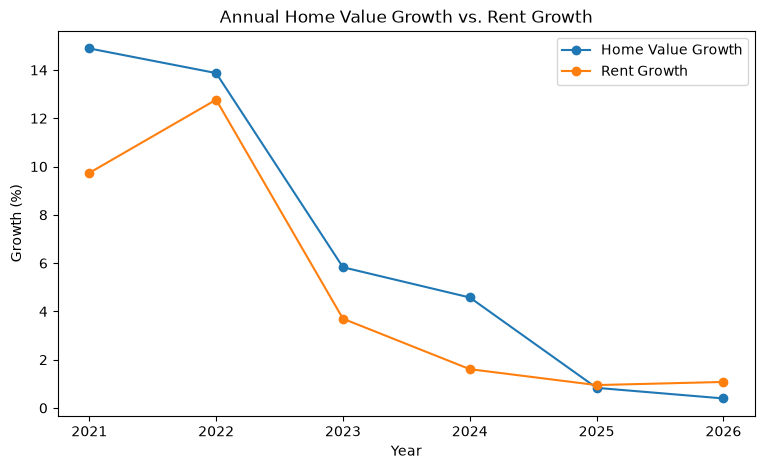

In [48]:
plt.figure(figsize=(9, 5))

plt.plot(
    annual.index,
    annual["home_growth"],
    marker="o",
    label="Home Value Growth"
)

plt.plot(
    annual.index,
    annual["rent_growth"],
    marker="o",
    label="Rent Growth"
)

plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.title("Annual Home Value Growth vs. Rent Growth")

plt.legend()
plt.show()

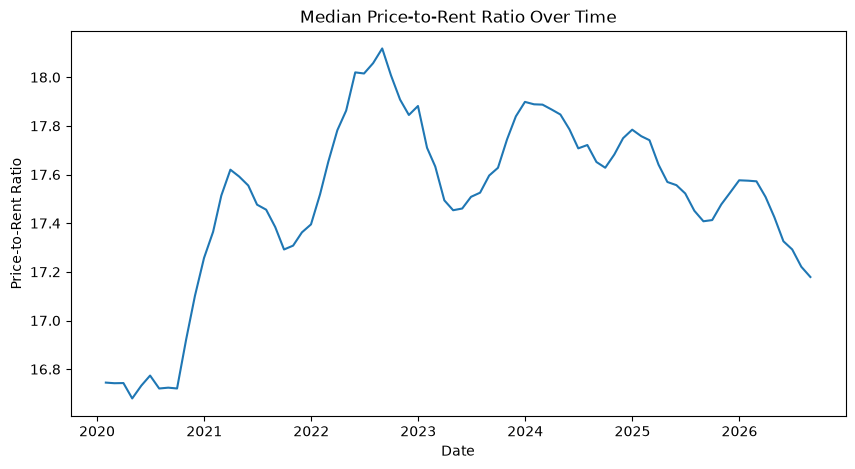

In [29]:
# Calculate the median PTR for each month
ptr_by_month = panel.groupby("date")["ptr"].median()

# Create the chart
plt.figure(figsize=(10, 5))

plt.plot(
    ptr_by_month.index,
    ptr_by_month.values
)

plt.title("Median Price-to-Rent Ratio Over Time")
plt.xlabel("Date")
plt.ylabel("Price-to-Rent Ratio")

plt.show()

In [30]:
# Create an index where January 2020 = 100

panel["zhvi_index"] = (
    panel["zhvi"] /
    panel.groupby("RegionID")["zhvi"].transform("first")
) * 100

panel["zori_index"] = (
    panel["zori"] /
    panel.groupby("RegionID")["zori"].transform("first")
) * 100

In [31]:
index_by_month = panel.groupby("date")[
    ["zhvi_index", "zori_index"]
].median()

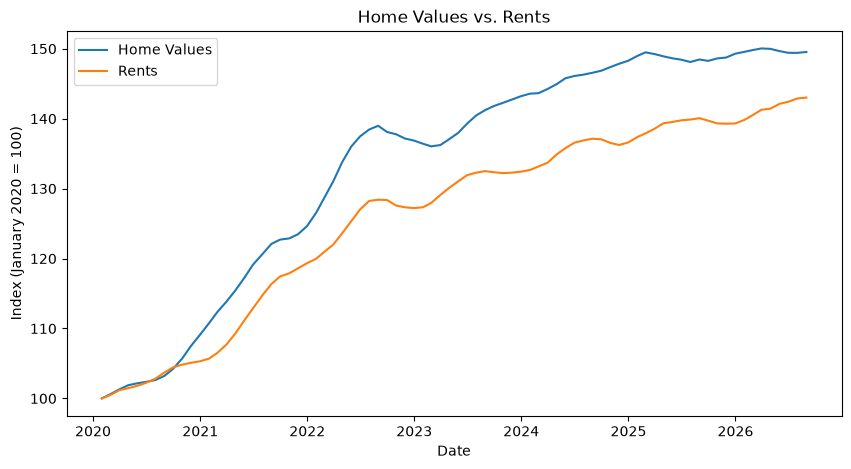

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    index_by_month.index,
    index_by_month["zhvi_index"],
    label="Home Values"
)

plt.plot(
    index_by_month.index,
    index_by_month["zori_index"],
    label="Rents"
)

plt.title("Home Values vs. Rents")
plt.xlabel("Date")
plt.ylabel("Index (January 2020 = 100)")

plt.legend()

plt.show()

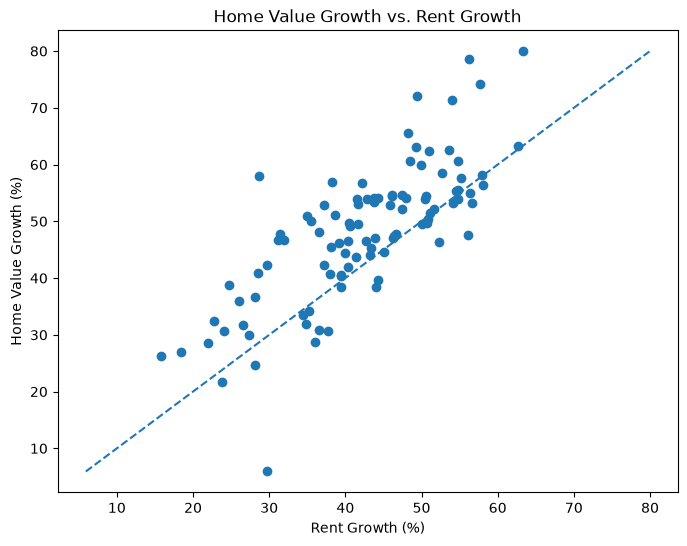

In [34]:
low = min(
    summary["rent_growth"].min(),
    summary["price_growth"].min()
)

high = max(
    summary["rent_growth"].max(),
    summary["price_growth"].max()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    summary["rent_growth"],
    summary["price_growth"]
)

plt.plot(
    [low, high],
    [low, high],
    "--"
)

plt.title("Home Value Growth vs. Rent Growth")
plt.xlabel("Rent Growth (%)")
plt.ylabel("Home Value Growth (%)")

plt.show()

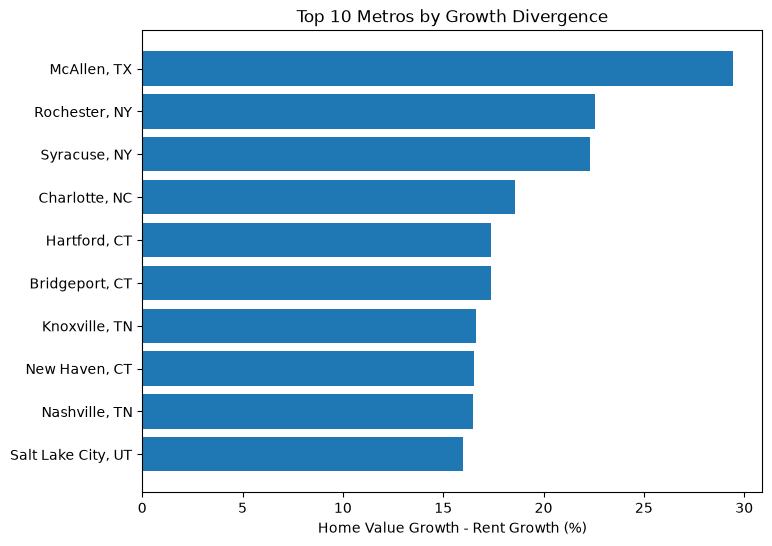

In [35]:
top10 = summary.sort_values(
    "divergence",
    ascending=False
).head(10)
plt.figure(figsize=(8, 6))

plt.barh(
    top10["RegionName"],
    top10["divergence"]
)

plt.title("Top 10 Metros by Growth Divergence")
plt.xlabel("Home Value Growth - Rent Growth (%)")

plt.gca().invert_yaxis()

plt.show()

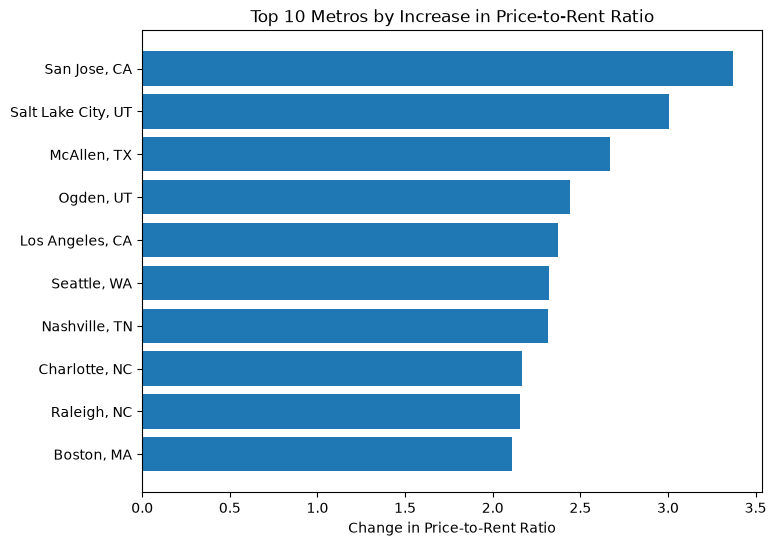

In [36]:
top10_ptr = summary.sort_values(
    "ptr_change",
    ascending=False
).head(10)
plt.figure(figsize=(8, 6))

plt.barh(
    top10_ptr["RegionName"],
    top10_ptr["ptr_change"]
)

plt.title("Top 10 Metros by Increase in Price-to-Rent Ratio")
plt.xlabel("Change in Price-to-Rent Ratio")

plt.gca().invert_yaxis()

plt.show()

In [37]:
panel["zhvi_yoy"] = (
    panel["zhvi"] /
    panel.groupby("RegionID")["zhvi"].shift(12)
    - 1
) * 100

panel["zori_yoy"] = (
    panel["zori"] /
    panel.groupby("RegionID")["zori"].shift(12)
    - 1
) * 100

In [38]:
lags = [0, 3, 6, 9, 12, 18, 24]

correlations = []

for lag in lags:

    future_price_growth = (
        panel.groupby("RegionID")["zhvi_yoy"]
        .shift(-lag)
    )

    data = pd.DataFrame({
        "rent_growth": panel["zori_yoy"],
        "future_price_growth": future_price_growth
    })

    data = data.dropna()

    correlation = data["rent_growth"].corr(
        data["future_price_growth"]
    )

    correlations.append(correlation)

lag_table = pd.DataFrame({
    "lag_months": lags,
    "correlation": correlations
})

lag_table

,lag_months,correlation
0,0,0.846687
1,3,0.800320
2,6,0.707213
3,9,0.585773
4,12,0.406101
5,18,0.129673
6,24,0.211150


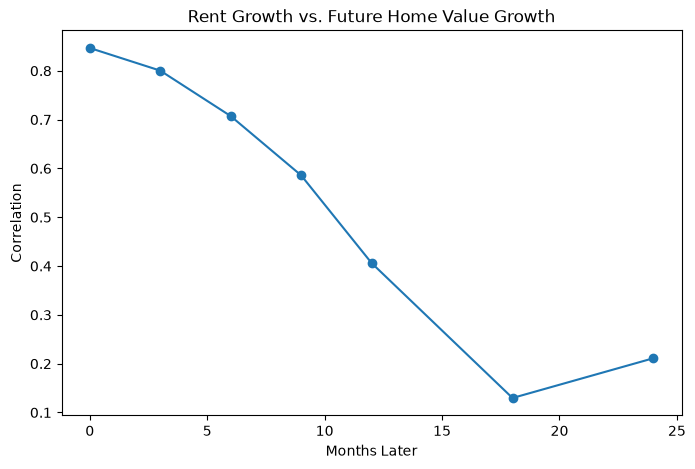

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    lag_table["lag_months"],
    lag_table["correlation"],
    marker="o"
)

plt.title("Rent Growth vs. Future Home Value Growth")
plt.xlabel("Months Later")
plt.ylabel("Correlation")

plt.show()

In [40]:
from sklearn.linear_model import LinearRegression
future_price_growth = (
    panel.groupby("RegionID")["zhvi_yoy"]
    .shift(-12)
)

regression_data = pd.DataFrame({
    "rent_growth": panel["zori_yoy"],
    "future_price_growth": future_price_growth
})

regression_data = regression_data.dropna()
regression_data.head()

,rent_growth,future_price_growth
12,7.836443,8.883396
13,8.803636,9.022900
14,8.184930,9.400364
15,8.180830,9.598987
16,8.560263,9.478382


In [41]:
X = regression_data[["rent_growth"]]
y = regression_data["future_price_growth"]
model = LinearRegression()
model.fit(X, y)
slope = model.coef_[0]
intercept = model.intercept_
r_squared = model.score(X, y)
print("Intercept:", round(intercept, 2))
print("Slope:", round(slope, 2))
print("R-squared:", round(r_squared, 3))

Intercept: 1.35
Slope: 0.54
R-squared: 0.165


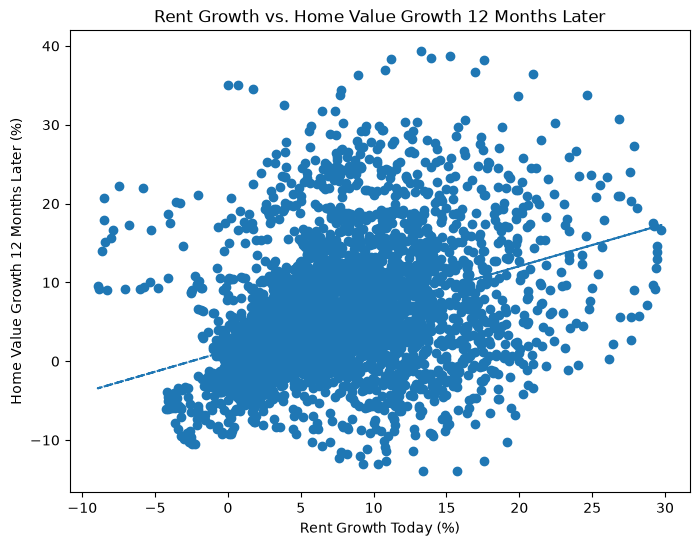

In [42]:
predicted = model.predict(X)
plt.figure(figsize=(8, 6))
plt.scatter(
    regression_data["rent_growth"],
    regression_data["future_price_growth"]
)
plt.plot(
    regression_data["rent_growth"],
    predicted,
    "--"
)
plt.title(
    "Rent Growth vs. Home Value Growth 12 Months Later"
)
plt.xlabel("Rent Growth Today (%)")
plt.ylabel(
    "Home Value Growth 12 Months Later (%)"
)
plt.show()

C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.p

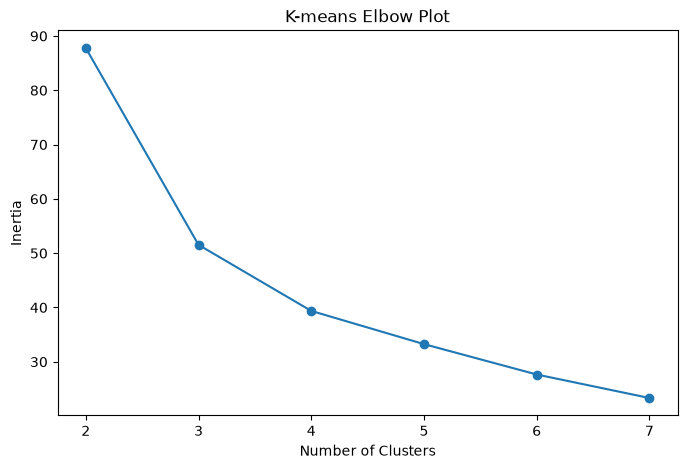

In [43]:
X = summary[
    ["price_growth", "rent_growth"]
]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
inertia = []
for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 8),
    inertia,
    marker="o"
)
plt.title("K-means Elbow Plot")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

In [44]:
k = 3
model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
summary["cluster"] = model.fit_predict(X_scaled)
cluster_summary = summary.groupby("cluster")[
    [
        "price_growth",
        "rent_growth",
        "divergence"
    ]
].mean()
cluster_summary

C:\Users\nguyenth\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,price_growth,rent_growth,divergence
cluster,,,
0,58.297366,52.779928,5.517437
1,30.620852,28.115512,2.505341
2,47.820436,40.271893,7.548542


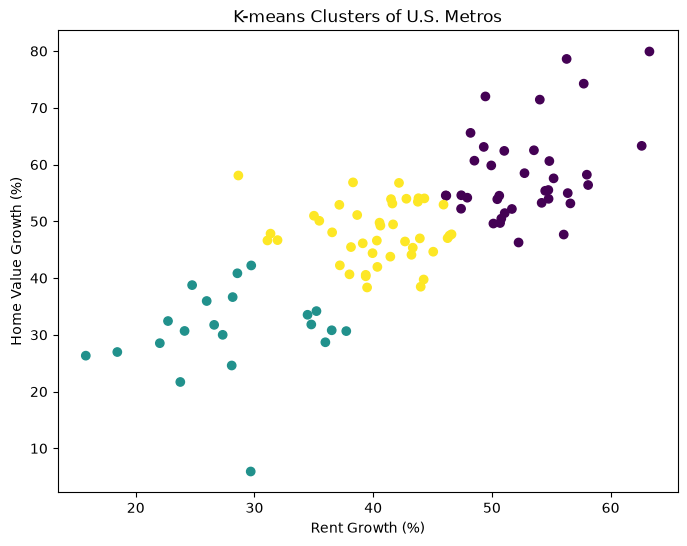

In [45]:
summary["cluster"].value_counts().sort_index()
plt.figure(figsize=(8, 6))
plt.scatter(
    summary["rent_growth"],
    summary["price_growth"],
    c=summary["cluster"]
)
plt.title("K-means Clusters of U.S. Metros")
plt.xlabel("Rent Growth (%)")
plt.ylabel("Home Value Growth (%)")
plt.show()

In [46]:
summary[
    [
        "RegionName",
        "price_growth",
        "rent_growth",
        "divergence",
        "cluster"
    ]
].sort_values("cluster")

,RegionName,price_growth,rent_growth,divergence,cluster
0,"Akron, OH",56.394705,58.105990,-1.711284,0
2,"Albuquerque, NM",62.519063,53.541901,8.977162,0
3,"Allentown, PA",62.410325,51.042428,11.367897,0
5,"Augusta, GA",52.174571,51.684808,0.489763,0
7,"Bakersfield, CA",53.154363,56.611664,-3.457301,0
...,...,...,...,...,...
65,"Philadelphia, PA",52.905462,37.149648,15.755814,2
94,"Wichita, KS",54.069675,43.814053,10.255622,2
90,"Tucson, AZ",44.099842,43.225482,0.874360,2
85,"St. Louis, MO",47.711679,46.599593,1.112085,2
